# 03 — Molecular subtype classification

We use the 20,481 expression features prepared in notebook 01 to predict the five known subtypes. This is a separate analysis from clustering with the 20 ICR genes.

We compare four ANOVA gene counts and several regularization settings for multiclass logistic regression. The final fit uses 2,000 selected genes and the value of `C` chosen for that gene count by cross-validation.


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, log_loss
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits


## Loading the split

The manifest contains 784 training samples, 197 test samples and five training folds. We check that no patient appears in both training and test. Samples without a subtype label are not used in classification.


In [ ]:
root=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
s=pd.read_csv(root/'data/interim/classification_split.csv').dropna(subset=['SUBTYPE']).set_index('SAMPLE_ID')
X=pd.read_parquet(root/'data/interim/expression_log2_rsem.parquet').reindex(s.index); y=s.SUBTYPE
train=s['split'].eq('train'); test=s['split'].eq('test')
Xtr=X.loc[train]; ytr=y.loc[train]; folds=s.loc[train,'validation_fold'].astype(int).to_numpy(); classes=sorted(y.unique())


## Model and candidate settings

The pipeline selects genes with ANOVA, standardizes them and fits logistic regression. We compare 20, 200, 2,000 and 20,000 genes. The model allows up to 1,000 iterations. The next cell defines the `C` values actually used in the search.


In [4]:
feature_counts = [20, 200, 2000, 20000]
C_values = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0, 3.0, 10.0]

def make_model(k, c):
    return make_pipeline(
        SelectKBest(f_classif, k=k),
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            C=c,
            random_state=42
        )
    )

print('Training:', len(ytr), 'test:', test.sum())

Training: 784 test: 197


## Cross-validation and log loss

We compare nine values of `C` for each gene count using the five training folds. For each fold, ANOVA scores and scaling are calculated on the four fitting folds and applied to the held-out fold.

Each point is the mean training or validation log loss across the five fits. Within a gene count and fold, models reuse the previous solution as a starting point when `C` changes. For each gene count we keep the `C` with the lowest mean validation loss.

The best validation loss for 2,000 genes occurs at `C=0.01`.


In [5]:
C_values = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0]
rows = []

with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    warnings.filterwarnings('ignore', category=UserWarning, module='sklearn.feature_selection')
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn.feature_selection')

    # Pre-calcola ANOVA e scaling UNA sola volta per fold
    fold_cache = {}
    for fold in sorted(np.unique(folds)):
        a = np.flatnonzero(folds != fold)
        b = np.flatnonzero(folds == fold)
        X_a, y_a = Xtr.iloc[a].to_numpy(), ytr.iloc[a].to_numpy()
        X_b, y_b = Xtr.iloc[b].to_numpy(), ytr.iloc[b].to_numpy()

        f_scores, _ = f_classif(X_a, y_a)
        order = np.argsort(np.nan_to_num(f_scores, nan=-1.0))[::-1]

        scaler = StandardScaler()
        X_a_s = scaler.fit_transform(X_a)
        X_b_s = scaler.transform(X_b)
        fold_cache[fold] = (X_a_s, y_a, X_b_s, y_b, order)

    for k in feature_counts:
        print(f"Running k={k:,}...", flush=True)
        # Inizializza un modello per fold con warm_start=True
        models = {
            fold: LogisticRegression(max_iter=1000, warm_start=True, random_state=42)
            for fold in fold_cache
        }
        for c in C_values:
            tr_losses, va_losses = [], []
            for fold, (X_a_s, y_a, X_b_s, y_b, order) in fold_cache.items():
                idx = order[:k]
                clf = models[fold]
                clf.set_params(C=c)
                clf.fit(X_a_s[:, idx], y_a)
                tr_losses.append(log_loss(y_a, clf.predict_proba(X_a_s[:, idx]), labels=classes))
                va_losses.append(log_loss(y_b, clf.predict_proba(X_b_s[:, idx]), labels=classes))
            rows.append({
                'genes': k,
                'C': c,
                'train_loss': np.mean(tr_losses),
                'val_loss': np.mean(va_losses)
            })

loss_df = pd.DataFrame(rows)
best_c_per_k = loss_df.loc[loss_df.groupby('genes')['val_loss'].idxmin()].set_index('genes')['C'].to_dict()
print("\nMiglior C per numero di geni:", best_c_per_k)
print(loss_df.loc[loss_df.groupby('genes')['val_loss'].idxmin()].to_string(index=False))

Running k=20...
Running k=200...
Running k=2,000...
Running k=20,000...

Miglior C per numero di geni: {20: 0.3, 200: 0.1, 2000: 0.01, 20000: 0.003}
 genes     C  train_loss  val_loss
    20 0.300    0.403191  0.484148
   200 0.100    0.084442  0.264830
  2000 0.010    0.055084  0.243884
 20000 0.003    0.023967  0.285867


## Loss table

This table lists the mean training and validation log loss for each combination of gene count and `C`. The same values are saved to CSV.


In [6]:
curve_all = loss_df
print(curve_all.round(4).to_string(index=False))

curve_all.to_csv(
    root / 'data/interim/15_curve_all_feature_counts.csv',
    index=False
)

 genes      C  train_loss  val_loss
    20 0.0001      1.1499    1.1509
    20 0.0003      1.0182    1.0201
    20 0.0010      0.8651    0.8691
    20 0.0030      0.7317    0.7396
    20 0.0100      0.6019    0.6177
    20 0.0300      0.5098    0.5384
    20 0.1000      0.4413    0.4928
    20 0.3000      0.4032    0.4841
    20 1.0000      0.3781    0.5011
   200 0.0001      0.8305    0.8388
   200 0.0003      0.6523    0.6667
   200 0.0010      0.4747    0.5004
   200 0.0030      0.3448    0.3883
   200 0.0100      0.2353    0.3115
   200 0.0300      0.1535    0.2740
   200 0.1000      0.0844    0.2648
   200 0.3000      0.0435    0.2845
   200 1.0000      0.0191    0.3309
  2000 0.0001      0.4863    0.5184
  2000 0.0003      0.3350    0.3910
  2000 0.0010      0.2065    0.3041
  2000 0.0030      0.1176    0.2611
  2000 0.0100      0.0551    0.2439
  2000 0.0300      0.0252    0.2468
  2000 0.1000      0.0100    0.2642
  2000 0.3000      0.0042    0.2873
  2000 1.0000      0.0016   

## Reading the loss curves

Each of the four panels represents one gene count. The x-axis is `C` on a log scale. The lines compare mean training and validation loss, and the dashed line marks the lowest validation loss among the tested values of `C`.


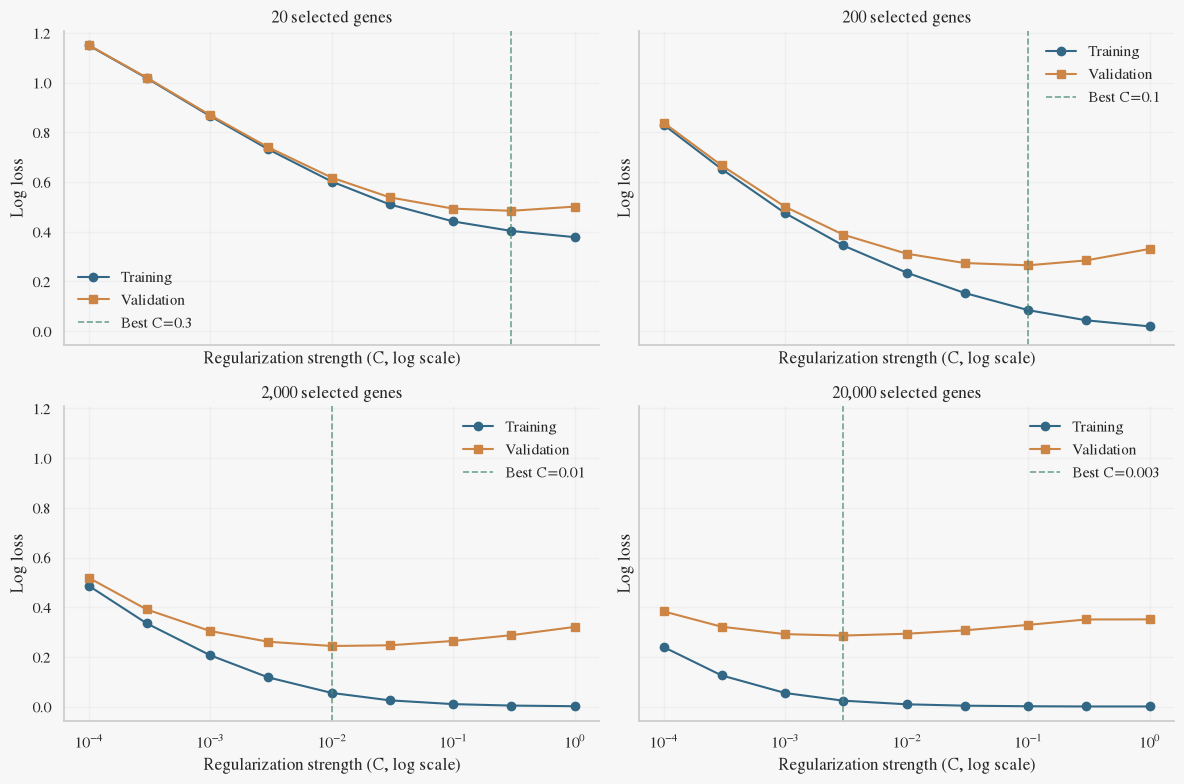

In [7]:
sns.set_theme(style='whitegrid', font_scale=1.0, rc={
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
    'figure.facecolor': '#f7f7f7',
    'axes.facecolor': '#f7f7f7',
    'savefig.facecolor': '#f7f7f7',
    'grid.alpha': .18
})

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, k in zip(axes, feature_counts):
    detail = curve_all.loc[curve_all.genes == k]
    best = detail.loc[detail.val_loss.idxmin()]

    ax.plot(detail.C, detail.train_loss, 'o-', label='Training', color='#326785')
    ax.plot(detail.C, detail.val_loss, 's-', label='Validation', color='#CC8545')
    ax.axvline(best.C, ls='--', lw=1.2, color='#508F75', alpha=0.8, label=f'Best C={best.C}')

    ax.set_xscale('log')
    ax.set(
        title=f'{k:,} selected genes',
        xlabel='Regularization strength (C, log scale)',
        ylabel='Log loss'
    )

    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.tight_layout()
fig.savefig(
    root / 'reports/figures/15_loss_comparison_feature_counts.png',
    dpi=180
)
plt.show()

## Comparing ANOVA feature counts

For each gene count, we use the `C` chosen above and make one out-of-fold prediction per training sample. The table reports accuracy, balanced accuracy and macro F1. 

In [8]:
# Compare ANOVA feature counts using the optimal C found via CV log loss for each k.
comparison = []
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    warnings.filterwarnings('ignore', category=UserWarning, module='sklearn.feature_selection')
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn.feature_selection')
    for k in feature_counts:
        c = best_c_per_k[k]
        pred = np.empty(len(ytr), dtype=object)
        for fold in sorted(np.unique(folds)):
            a = np.flatnonzero(folds != fold)
            b = np.flatnonzero(folds == fold)
            model = make_model(k, c)
            model.fit(Xtr.iloc[a], ytr.iloc[a])
            pred[b] = model.predict(Xtr.iloc[b])
        comparison.append({
            'genes': k,
            'C': c,
            'accuracy': accuracy_score(ytr, pred),
            'balanced_accuracy': balanced_accuracy_score(ytr, pred),
            'macro_f1': f1_score(ytr, pred, average='macro')
        })

anova_comparison = pd.DataFrame(comparison)
print(anova_comparison.to_string(index=False))
anova_comparison.to_csv(root / 'data/interim/03_anova_feature_count_cv.csv', index=False)

 genes     C  accuracy  balanced_accuracy  macro_f1
    20 0.300  0.803571           0.708800  0.739495
   200 0.100  0.899235           0.804543  0.831666
  2000 0.010  0.895408           0.815877  0.838733
 20000 0.003  0.876276           0.769195  0.796559


### Comparing the scores

The figure compares out-of-fold scores for the four gene counts, each with its selected `C`. The test set is not used to draw this figure.


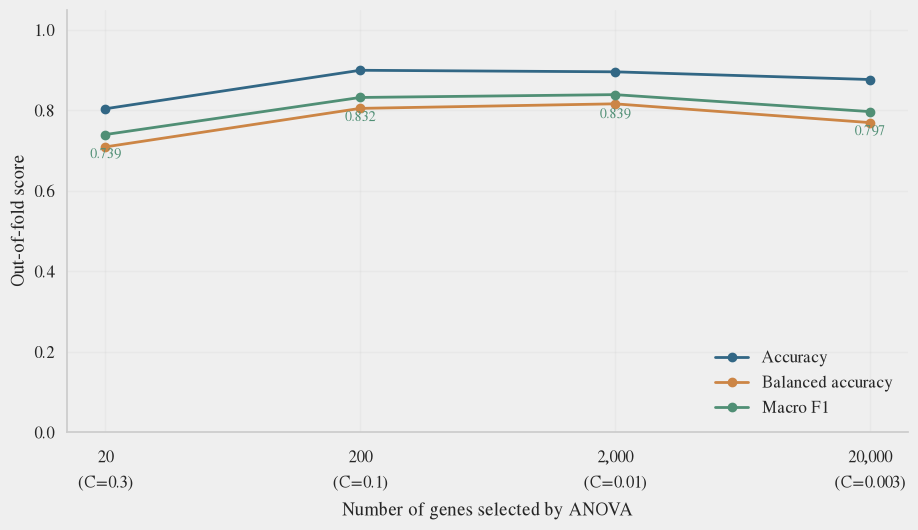

In [9]:
sns.set_theme(
    style='whitegrid', font_scale=1.1,
    rc={'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix',
        'figure.facecolor': '#efefef', 'axes.facecolor': '#efefef',
        'savefig.facecolor': '#efefef', 'grid.alpha': .2}
)
fig, ax = plt.subplots(figsize=(9.4, 5.5))
for col, label, color in [
    ('accuracy', 'Accuracy', '#326785'),
    ('balanced_accuracy', 'Balanced accuracy', '#CC8545'),
    ('macro_f1', 'Macro F1', '#508F75')
]:
    ax.plot(range(len(feature_counts)), anova_comparison[col], marker='o', lw=2, label=label, color=color)
    if col == 'macro_f1':
        for x, v in enumerate(anova_comparison[col]):
            ax.annotate(f'{v:.3f}', (x, v), textcoords='offset points', xytext=(0, -17), ha='center', fontsize=10, color=color)

xlabels = [f"{k:,}\n(C={best_c_per_k[k]})" for k in feature_counts]
ax.set_xticks(range(len(feature_counts)), labels=xlabels)
ax.set(xlabel='Number of genes selected by ANOVA', ylabel='Out-of-fold score', ylim=(0, 1.05))
ax.legend(frameon=False, loc='lower right')
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(root / 'reports/figures/108_anova_gene_count_cv.png', dpi=180)
plt.show()

## Test results

We fit the 2,000-gene pipeline with the selected `C` on all 784 training samples and predict the 197 test samples. The saved output gives accuracy 93.40%, balanced accuracy 0.8774 and macro F1 0.9069. The saved `C` selected for 2,000 genes is 0.01.

The test results were examined during development, so this is not a blind test. An independent cohort would give a better measure of generalization.


In [10]:
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    # Alcuni geni sono costanti nel training: ANOVA assegna loro un punteggio non selezionabile.
    warnings.filterwarnings('ignore', message='Features .* are constant', category=UserWarning)
    warnings.filterwarnings('ignore', message='invalid value encountered in divide', category=RuntimeWarning)
    final = make_model(2000, best_c_per_k[2000])  # C=0.01, max_iter=1000
    final.fit(Xtr, ytr)
    testpred = final.predict(X.loc[test])

sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [    5   616  3514  4323  4356  4360  4361  4362  4637  4638  4639  4799
  4801  4803  4808  5269  6008  6054  7638  7639  7640  7641  7642  9270
  9279  9282  9284  9286  9291  9293  9298  9425 10088 11647 11918 13478
 13949 14116 14117 14118 14119 14174 14712 14713 14714 14715 14716 14717
 14718 14719 14720 15096 15098 15099 15260 15405 16521 16522 16523 16525
 16526 16528 16532 16533 16559 16588 16592 16632 16651 16652 16653 16654
 16655 16657 16658 16659 16660 16661 16662 16663 16664 16665 16666 16667
 16668 16669 16670 16671 16672 16673 16674 16675 16676 16677 16678 16679
 16680 16681 16682 16683 16684 16685 16686 16687 16688 16689 16690 16691
 16692 16693 16694 16695 16696 16697 16698 16699 16700 16702 16703 16704
 16705 16706 16707 16708 16709 16711 16712 16713 16714 16715 16716 16717
 16718 16719 16720 16721 16722 16723 16724 16725 16726 16728 16729 16730
 16731 16732 16733 16734 16735 16736 16737 167

## Per-class results

We look at precision and recall for each subtype as well as overall accuracy. A comparison with rebalancing would need to fit those methods within the training folds.


In [11]:
yt=y.loc[test]
print('TEST ESPLORATIVO: accuracy',round(accuracy_score(yt,testpred),4),'balanced accuracy',round(balanced_accuracy_score(yt,testpred),4),'macro F1',round(f1_score(yt,testpred,average='macro'),4))
print(classification_report(yt,testpred,zero_division=0))


TEST ESPLORATIVO: accuracy 0.934 balanced accuracy 0.8774 macro F1 0.9069
              precision    recall  f1-score   support

  BRCA_Basal       1.00      1.00      1.00        34
   BRCA_Her2       0.93      0.81      0.87        16
   BRCA_LumA       0.93      0.96      0.95       100
   BRCA_LumB       0.88      0.90      0.89        40
 BRCA_Normal       1.00      0.71      0.83         7

    accuracy                           0.93       197
   macro avg       0.95      0.88      0.91       197
weighted avg       0.93      0.93      0.93       197



## Model coefficients

The heatmap shows fitted coefficients for 15 selected genes with the largest range across classes. Coefficients use standardized expression and describe the fitted model, not causal gene effects.


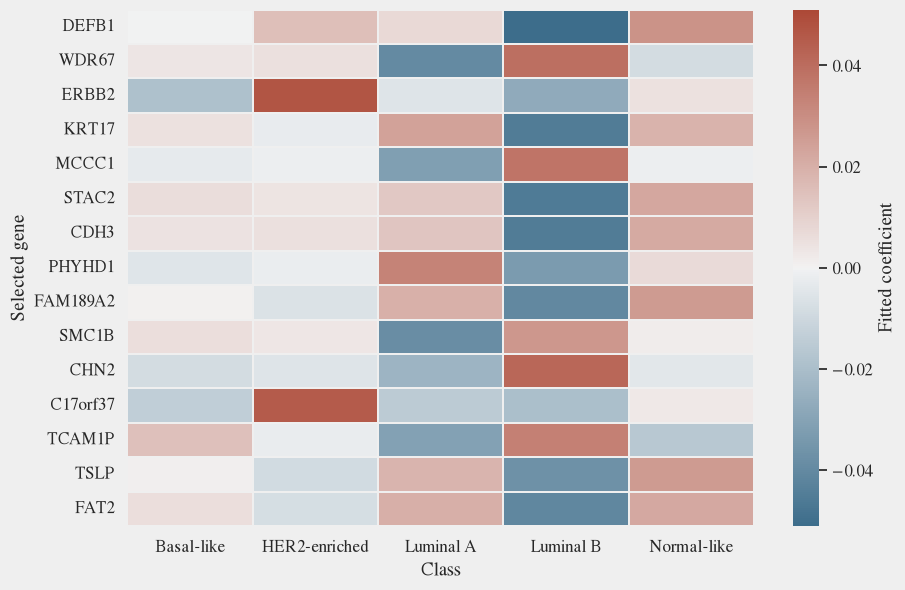

Top coefficient-spread genes: ['DEFB1', 'WDR67', 'ERBB2', 'KRT17', 'MCCC1', 'STAC2', 'CDH3', 'PHYHD1', 'FAM189A2', 'SMC1B', 'CHN2', 'C17orf37', 'TCAM1P', 'TSLP', 'FAT2']


In [12]:
# Coefficients from the fitted 2,000-gene logistic regression.
selector = final.named_steps['selectkbest']
classifier = final.named_steps['logisticregression']
gene_columns = Xtr.columns[selector.get_support(indices=True)]
names = {'BRCA_Basal':'Basal-like','BRCA_Her2':'HER2-enriched','BRCA_LumA':'Luminal A','BRCA_LumB':'Luminal B','BRCA_Normal':'Normal-like'}
sns.set_theme(style='whitegrid',font_scale=1.1,rc={'font.family':'STIXGeneral','mathtext.fontset':'stix','figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef','grid.alpha':.18})
W=classifier.coef_;top=np.argsort(np.ptp(W,axis=0))[-15:][::-1];ann=pd.read_csv(root/'data/interim/gene_annotations.csv')
symbol_map=ann.set_index(ann.Entrez_Gene_Id.astype(str)).Hugo_Symbol.to_dict()
gene_labels=[str(symbol_map.get(str(gene_columns[j])) or str(gene_columns[j])) for j in top]
weights=pd.DataFrame(W[:,top].T,index=gene_labels,columns=[names[c] for c in classifier.classes_]);limit=np.nanmax(np.abs(weights.to_numpy()))
fig,ax=plt.subplots(figsize=(9.4,6.1));sns.heatmap(weights,cmap=sns.diverging_palette(235,18,s=70,l=44,as_cmap=True),center=0,vmin=-limit,vmax=limit,linewidths=.25,linecolor='#efefef',cbar_kws={'label':'Fitted coefficient'},ax=ax);ax.set(xlabel='Class',ylabel='Selected gene');ax.tick_params(axis='x',rotation=0);ax.tick_params(axis='y',rotation=0);fig.tight_layout();fig.savefig(root/'reports/figures/112_coefficient_heatmap.png',dpi=180);plt.show()
print('Top coefficient-spread genes:',gene_labels)


## Softmax along training-subtype mean profiles

Each class centroid is the mean standardized expression profile of its training samples after gene selection. The plotted path connects the centroids in this chosen order: Luminal A, Luminal B, HER2-enriched, Basal-like, Normal-like. The profiles between centroids are interpolated, not real samples. The curves show the fitted model’s probabilities along this path.


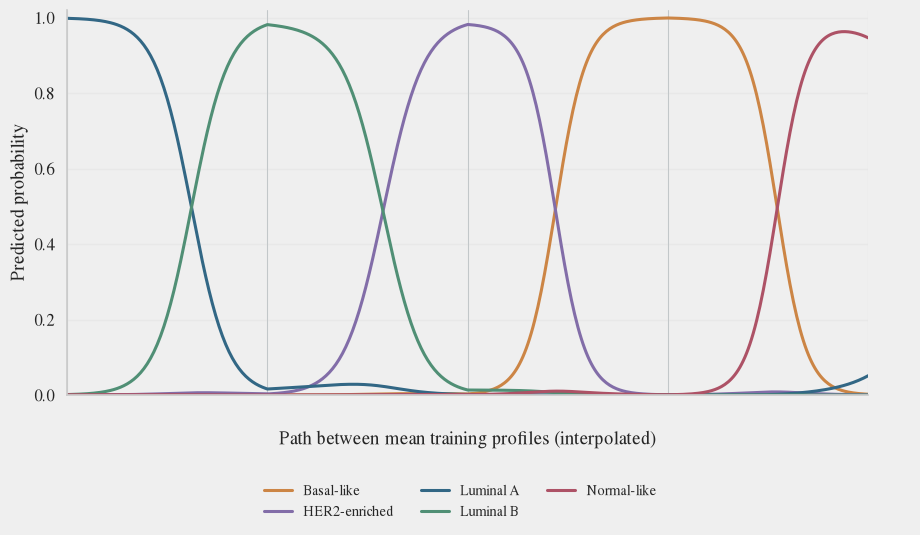

Probabilities on training-set class centroids:
               Basal-like  HER2-enriched  Luminal A  Luminal B  Normal-like
Luminal A           0.000          0.000      0.998      0.001        0.001
Luminal B           0.000          0.003      0.016      0.981        0.000
HER2-enriched       0.003          0.982      0.001      0.013        0.001
Basal-like          0.999          0.001      0.000      0.000        0.001
Normal-like         0.002          0.001      0.051      0.000        0.946


In [13]:
# Softmax of the fitted model along a path through training-class centroids.
# This is a deliberately chosen, piecewise-linear path in the 2,000-gene space.
selector=final.named_steps['selectkbest'];scaler=final.named_steps['standardscaler'];classifier=final.named_steps['logisticregression']
Ztrain=scaler.transform(selector.transform(Xtr))
order=['BRCA_LumA','BRCA_LumB','BRCA_Her2','BRCA_Basal','BRCA_Normal']
short={'BRCA_Basal':'Basal-like','BRCA_Her2':'HER2-enriched','BRCA_LumA':'Luminal A','BRCA_LumB':'Luminal B','BRCA_Normal':'Normal-like'}
centers=np.vstack([Ztrain[ytr.eq(cls).to_numpy()].mean(axis=0) for cls in order])
segments=120;path=[];positions=[]
for j in range(len(order)-1):
 for t in np.linspace(0,1,segments,endpoint=False):
  path.append((1-t)*centers[j]+t*centers[j+1]);positions.append(j+t)
path.append(centers[-1]);positions.append(len(order)-1)
prob=classifier.predict_proba(np.asarray(path));assert np.allclose(prob.sum(axis=1),1)
colors={'BRCA_Basal':'#CC8545','BRCA_Her2':'#826DA8','BRCA_LumA':'#326785','BRCA_LumB':'#508F75','BRCA_Normal':'#AD5266'}
sns.set_theme(style='whitegrid',font_scale=1.1,rc={'font.family':'STIXGeneral','mathtext.fontset':'stix','figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef','grid.alpha':.18})
fig,ax=plt.subplots(figsize=(9.4,5.5))
for j,cls in enumerate(classifier.classes_):ax.plot(positions,prob[:,j],lw=2.2,color=colors[cls],label=short[cls])
ax.set_xticks(range(5),[short[c] for c in order]);ax.tick_params(axis='x',labelcolor='#efefef');ax.set(xlim=(0,4),ylim=(0,1.02),ylabel='Predicted probability',xlabel='Path between mean training profiles (interpolated)')
for x in range(5):ax.axvline(x,color='#869399',lw=.7,alpha=.45,zorder=0)
fig.legend(*ax.get_legend_handles_labels(),ncol=3,frameon=False,loc='lower center',bbox_to_anchor=(.5,.015),fontsize=10);sns.despine(ax=ax);fig.tight_layout(rect=[0,.13,1,1]);fig.savefig(root/'reports/figures/109_softmax_curves.png',dpi=180);plt.show()
anchor_prob=classifier.predict_proba(centers);print('Probabilities on training-set class centroids:');print(pd.DataFrame(anchor_prob,index=[short[c] for c in order],columns=[short[c] for c in classifier.classes_]).round(3).to_string())
pd.DataFrame({'position':positions,**{short[c]:prob[:,j] for j,c in enumerate(classifier.classes_)}}).to_csv(root/'data/interim/03_softmax_curves.csv',index=False)


## Predicted probabilities for real test samples

Each line connects different test samples ordered by DEFB1 expression. The probabilities use all 2,000 selected genes, so these lines do not describe a continuous response to DEFB1 alone. The test samples were already examined during development.


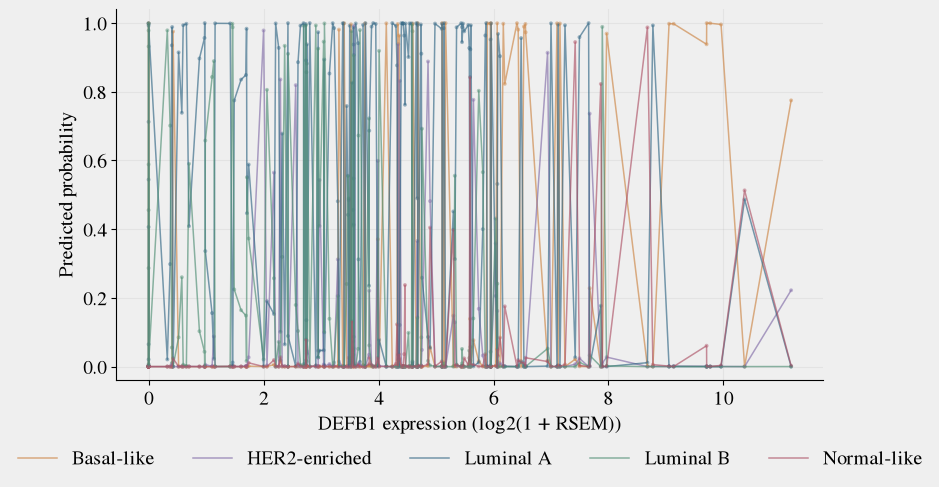

In [ ]:
# Plot all five probabilities for each real test sample ordered by DEFB1 expression.
probs = final.predict_proba(X.loc[test])
annotation = pd.read_csv(root / 'data/interim/gene_annotations.csv')
defb1_id = str(int(annotation.loc[annotation.Hugo_Symbol.eq('DEFB1'), 'Entrez_Gene_Id'].dropna().iloc[0]))
expression = X.loc[test, defb1_id].to_numpy()
order_by_expression = np.argsort(expression, kind='stable')

plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
    'figure.facecolor': '#efefef',
    'axes.facecolor': '#efefef',
    'font.size': 14
})
fig, ax = plt.subplots(figsize=(9.4, 5.5))
for j, cls in enumerate(final.classes_):
    ax.plot(expression[order_by_expression], probs[order_by_expression, j], lw=1.1, alpha=.65, color=colors[cls], label=short[cls])
    ax.scatter(expression, probs[:, j], s=8, alpha=.45, color=colors[cls], edgecolors='none')

ax.set(xlabel='DEFB1 expression (log2(1 + RSEM))', ylabel='Predicted probability', ylim=(-.04, 1.04))
ax.grid(alpha=.18)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(ncol=5, frameon=False, loc='upper center', bbox_to_anchor=(.5, -.14))
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(root / 'reports/figures/softmax_real_test_defb1_en.png', dpi=200, bbox_inches='tight')
plt.show()

## Confusion matrices

Rows show known subtypes and columns show predictions. In the saved test output, five of seven Normal-like samples are correctly classified and two are predicted as Luminal A. With seven samples, one error changes recall by about 14 percentage points.

The training matrix combines out-of-fold predictions from five models. Its `C` was selected using the same folds.


Validazione incrociata 
              BRCA_Basal  BRCA_Her2  BRCA_LumA  BRCA_LumB  BRCA_Normal
BRCA_Basal          133          2          0          1            1
BRCA_Her2             1         52          3          6            0
BRCA_LumA             0          2        374         19            4
BRCA_LumB             0          2         27        128            0
BRCA_Normal           1          0         11          2           15
Test esplorativo 
              BRCA_Basal  BRCA_Her2  BRCA_LumA  BRCA_LumB  BRCA_Normal
BRCA_Basal           34          0          0          0            0
BRCA_Her2             0         13          2          1            0
BRCA_LumA             0          0         96          4            0
BRCA_LumB             0          1          3         36            0
BRCA_Normal           0          0          2          0            5


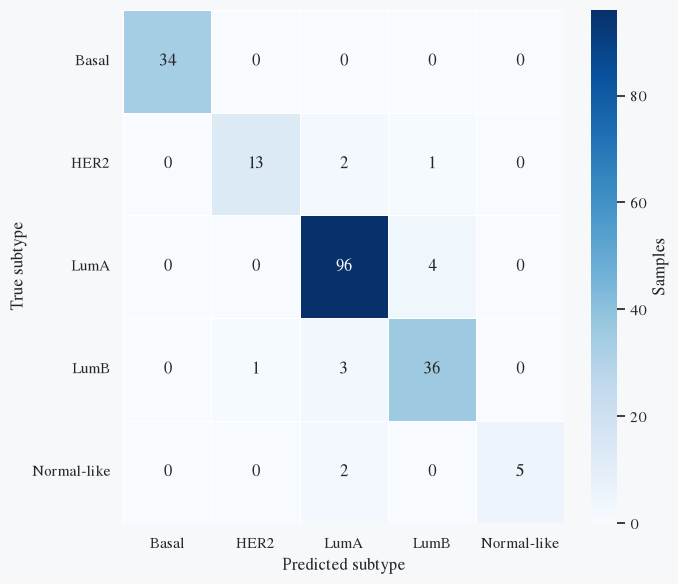

In [15]:
cvpred = np.empty(len(ytr), dtype=object)
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    warnings.filterwarnings('ignore', category=UserWarning, module='sklearn.feature_selection')
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn.feature_selection')
    for fold in sorted(np.unique(folds)):
        a = np.flatnonzero(folds != fold)
        b = np.flatnonzero(folds == fold)
        m = make_model(2000, best_c_per_k[2000])
        m.fit(Xtr.iloc[a], ytr.iloc[a])
        cvpred[b] = m.predict(Xtr.iloc[b])

sns.set_theme(style='whitegrid', font_scale=1.0, rc={
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
    'figure.facecolor': '#f7f8f9',
    'axes.facecolor': '#f7f8f9',
    'savefig.facecolor': '#f7f8f9',
    'grid.alpha': .2
})

# Salviamo entrambe le matrici; quella del test è visualizzata nelle slide.
for actual, prediction, title, fname in [(ytr, cvpred, 'Validazione incrociata', 'cv'), (yt, testpred, 'Test esplorativo', 'test')]:
    matrix = confusion_matrix(actual, prediction, labels=classes)
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(root / f'data/interim/15_{fname}_confusion.csv')
    print(title, '\n', pd.DataFrame(matrix, index=classes, columns=classes).to_string())

cm = confusion_matrix(yt, testpred, labels=classes)
class_names = ['Basal', 'HER2', 'LumA', 'LumB', 'Normal-like']
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', linewidths=.5, linecolor='white',
    xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Samples'}, ax=ax
)
ax.set(xlabel='Predicted subtype', ylabel='True subtype')
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', rotation=0)
fig.tight_layout()
fig.savefig((root / 'reports/figures') / '77_en_test_confusion.png', dpi=180)
plt.show()